# 512-point 16-bit FFT Simulation

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# define some helpful functions:
def plot_complex(X, ax, title):
    """
    plot a complex variable `X` on axis `ax` with title `title`.
    """
    re = ax.plot(np.real(X), 'x-', label='real')
    im = ax.plot(np.imag(X), 'x-', label='imag')
    ax.legend()
    ax.set_title(title)
    return re, im

def to_int(hexstr, bits):
    """
    Convert `bits`-bit representation twos-complement hex string `hexstr` to an integer.   
    from https://stackoverflow.com/a/6727975/6115747.
    """
    value = int(hexstr, 16)
    if value & (1 << (bits - 1)):
        value -= 1 << bits
    return value

def int2hex(integer, digits):
    """
    Convert integer `integer` to `digits`-bit two's complement hex representation.
    """
    if integer >= 0:
        return hex(integer)[2:].zfill(digits)
    else:
        return hex(2**(4*digits) + integer)[2:]

# Generate test case `x`:

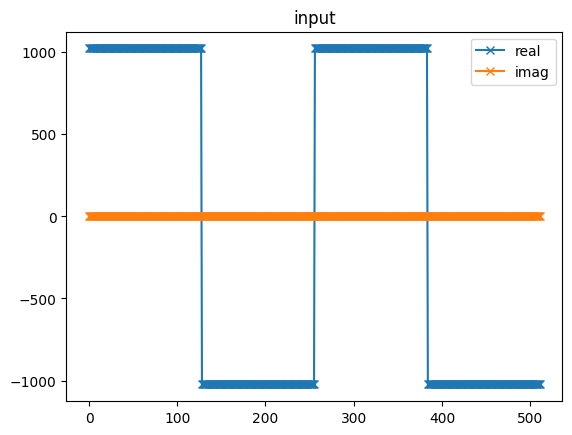

In [20]:
## square wave w/ 512 points (yay) and 1023/-1024 
x = np.concatenate((1023*np.ones(128, dtype='int16'), -1024*np.ones(128, dtype='int16'), 1023*np.ones(128, dtype='int16'), -1024*np.ones(128, dtype='int16')))

## all ones (DC)
# x = (2**10-1) * np.ones(32, dtype='int16')

## Cos wave
# x = ((2**10-1) * np.cos(np.arange(32)*2*np.pi/32)).astype('int16')

fig, ax = plt.subplots()
_ = plot_complex(x, ax, "input")

### write `x` to `test_in.memh`:
This is is the input file used by the testbench in ModelSim.

In [21]:
with open("test_in.memh", "w") as f:
    for sample in x:
        f.write(int2hex(int(np.real(sample)), 4) + int2hex(int(np.imag(sample)), 4) + "\n")

# Generate Ground Truth Output:
Both fixed-point and NumPy (floating point) ground-truth outputs are evaluated.

## Fixed-point (bit-accurate) FFT:

In [22]:
import numpy as np          
import shutil, os

#based off original one in Brake paper, but edited by Claude to clip to the correct number of bits (7)
def s16(v):
    v &= 0xFFFF
    return v - 65536 if v >= 32768 else v

def load_mem(path):
    """Read a .mem file (32-bit hex per line, real in the upper half) into a complex array."""
    re, im = [], []
    for line in open(path):
        line = line.strip()
        if not line:
            continue
        w = int(line, 16)
        re.append(s16(w >> 16))
        im.append(s16(w & 0xFFFF))
    return np.array(re) + 1j * np.array(im)

def write_clipped_mem(x, path="test_in.memh"):
    """Clip x to signed 7 bits, write it to a .mem file, and return the clipped array."""
    # clip input to 7-bit signed range
    xr = np.clip(np.real(x).astype('int64'), -64, 63)
    xi = np.clip(np.imag(x).astype('int64'), -64, 63)

    if os.path.exists(path):                       # keep the original once
        shutil.copy(path, path + ".orig")

    with open(path, "w") as f:
        for r, i in zip(xr, xi):
            f.write("%04x%04x\n" % (int(r) & 0xFFFF, int(i) & 0xFFFF))

    return xr + 1j * xi

# usage, starting from the file the RTL currently loads:
x = load_mem("test_in.memh")
x_clipped = write_clipped_mem(x, "test_in.memh")   # overwrites test_in.mem (backup in test_in.mem.orig)

def fpFFT(x):
    """
    Fixed-point FFT, N = 512, 16-bit data words.
    Input is clipped to signed 7 bits (-64..63) so that the 9 bits of
    growth over 9 stages fit in 16 bits.
    """
    N, STAGES = 512, 9

    # clip input to 7-bit signed range
    xr = np.clip(np.real(x).astype('int64'), -64, 63)
    xi = np.clip(np.imag(x).astype('int64'), -64, 63)


    # bit-reversed load into 16-bit arrays
    Data_r = np.zeros(N, 'int16')
    Data_i = np.zeros(N, 'int16')
    for i in range(N):
        j = int(f'{i:09b}'[::-1], 2)
        Data_r[i] = xr[j]
        Data_i[i] = xi[j]

    # twiddle factors (Q15)
    n = np.arange(N)
    Tw_r = (np.cos(2*np.pi*n/N)  * (2**15 - 1)).astype('int64')
    Tw_i = (-np.sin(2*np.pi*n/N) * (2**15 - 1)).astype('int64')

    stages = []
    # butterflies
    for i in range(STAGES):
        for j in range(N // 2):
            ja = j << 1
            jb = ja + 1
            ja = ((ja << i) | (ja >> (STAGES - i))) & 0x1ff
            jb = ((jb << i) | (jb >> (STAGES - i))) & 0x1ff
            TwAddr = ((0xffffff00 >> i) & 0xff) & j

            br, bi = int(Data_r[jb]), int(Data_i[jb])
            wr, wi = int(Tw_r[TwAddr]), int(Tw_i[TwAddr])
            ar, ai = int(Data_r[ja]), int(Data_i[ja])

            temp_r = int(round(br * wr / 32768)) - int(round(bi * wi / 32768))
            temp_i = int(round(br * wi / 32768)) + int(round(bi * wr / 32768))

            Data_r[jb] = ar - temp_r
            Data_i[jb] = ai - temp_i
            Data_r[ja] = ar + temp_r
            Data_i[ja] = ai + temp_i
            stages.append((Data_r.copy(), Data_i.copy()))

    with open("stages.txt", "w") as f:
        for sample in stages:
            f.write(str(sample) + "\n")
            
    return Data_r + 1j*Data_i

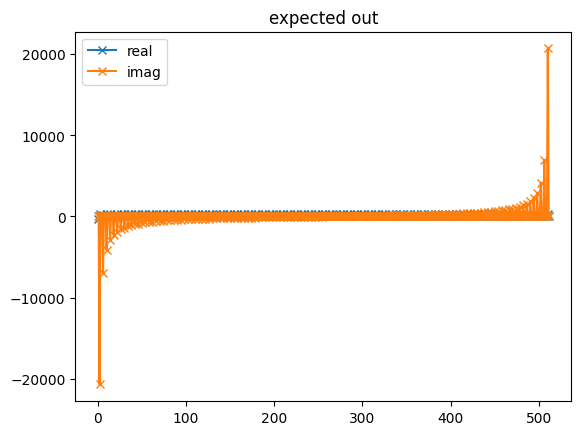

In [23]:
X = fpFFT(x)
fig, ax = plt.subplots()
_ = plot_complex(X, ax, "expected out")

## NumPy (floating point) FFT:

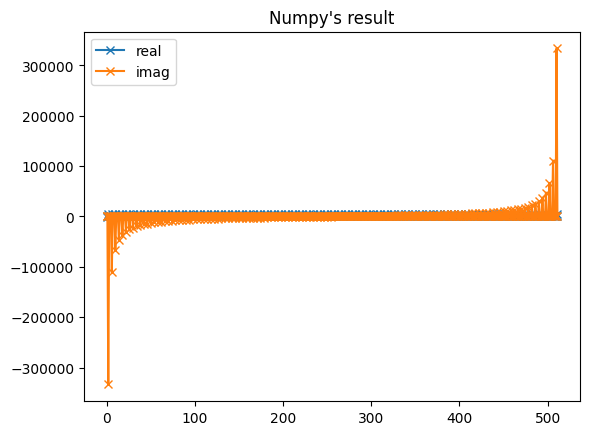

In [24]:
numpy_out = np.fft.fft(x)
fig, ax = plt.subplots()
_ = plot_complex(numpy_out, ax, "Numpy's result")

In [25]:
# note that due to fixed- vs. floating- point differences,
# numpy and our reference implementation yield slightly different results
numpy_out - X

array([   0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3840.-3.12881385e+05j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3871.-1.04233799e+05j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3827.-6.24900706e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3832.-4.45911609e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3852.-3.46288359e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3840.-2.82706620e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3837.-2.38631599e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3840.-2.06258348e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000e+00j,
       3838.-1.81405385e+04j,    0.+0.00000000e+00j,
          0.+0.00000000e+00j,    0.+0.00000000

### write to `simulation/modelsim/rom/gt_test_out.memh`:
This is the bit-accurate ground-truth output that the ModelSim testbench uses.

In [26]:
with open("gt_test_out.memh", "w") as f:
    for sample in X:
        f.write(int2hex(int(np.real(sample)), 4) + int2hex(int(np.imag(sample)), 4) + "\n")

# Evaluate the Hardware Implementation's output:
Note that the `fft_testbench` needs to be run to completion in modelsim in order to generate the file!

In [27]:
# read in file from the FFT test bench -- need to copy-paste test_out values if using jacquard 
df = pd.read_csv("test_out.mem", sep=r"\s+", header=None, dtype=str)
out = df.drop(df.columns[0:2], axis=1)      # remove annoying extra columns that come with output on jacquard
words_array = out.iloc[:, 0].to_numpy()      # 1-D numpy array
new_out = np.array([to_int(w[0:4], 16) + 1j * to_int(w[4:8],16) for w in words_array])

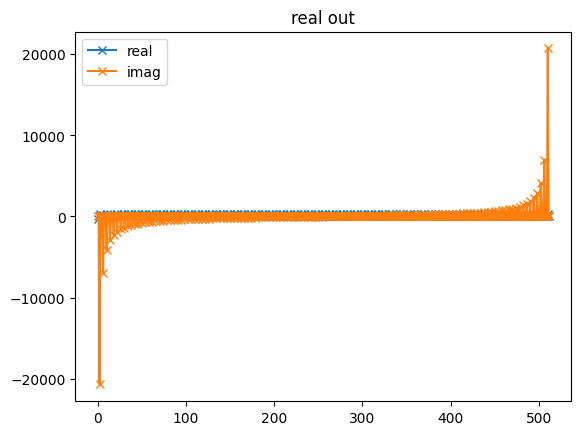

In [28]:
fig, ax = plt.subplots()
_ = plot_complex(new_out, ax, "real out")

## Compare Hardware and Python Fixed-Point Implementations:

In [29]:
X - new_out

array([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
       0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
      

# Generate Figure:

c:\Users\Katie\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Katie\AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


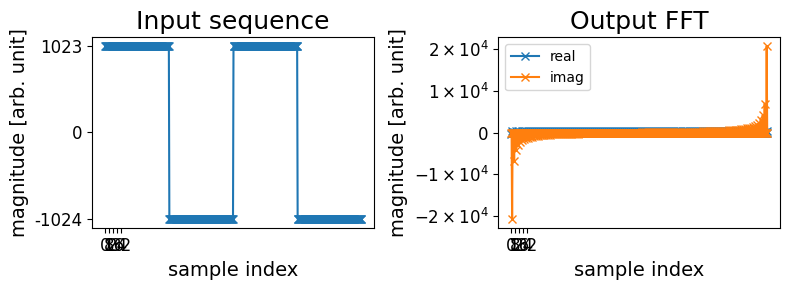

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3))
tsize = 18
lsize = 14
xsize = 12

axs[0].plot(x, 'x-')
axs[0].set_title("Input sequence", fontsize=tsize)
axs[0].set_xticks([0, 8, 16, 24, 32])
axs[0].set_xticklabels([0, 8, 16, 24, 32], fontsize=xsize)
axs[0].set_yticks([-1024, 0, 1023])
axs[0].set_yticklabels([-1024, 0, 1023], fontsize=xsize)
axs[0].set_xlabel("sample index", fontsize=lsize)
axs[0].set_ylabel("magnitude [arb. unit]", fontsize=lsize)

plot_complex(new_out, axs[1], "")
axs[1].set_title("Output FFT", fontsize=tsize)
axs[1].set_xlabel("sample index", fontsize=lsize)
axs[1].set_ylabel("magnitude [arb. unit]", fontsize=lsize)
axs[1].set_xticks([0, 8, 16, 24, 32])
axs[1].set_xticklabels([0, 8, 16, 24, 32], fontsize=xsize)
axs[1].set_yticks(     [-20000, -10000, 0, 10000, 20000])
axs[1].set_yticklabels([r"$-2 \times 10^4$", r"$-1 \times 10^4$", 
                        r"$0$", 
                        r"$1 \times 10^4$", r"$2 \times 10^4$"], fontsize=xsize)

plt.tight_layout()
plt.savefig('test_case.pdf')  